1. get the age_group feature (check Carol's code)
2. make an IterativeImputer for group 1.
3. then group 2, 3, 4 in that order.
4. confirm that there are no missing numerical values.
5. check the new correlation values.

In [36]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.experimental import enable_iterative_imputer
data = pd.read_csv("tmp_datasets/outlier_removed.csv")
target = "inhospital_mortality"

data = pd.read_csv("../../preliminar_phase_submision/training_data/SyntheticData_Training.csv")
dictionary = pd.read_csv("tmp_datasets/DataDictionary.csv")
target = "inhospital_mortality"

continuous_features = dictionary[(dictionary['Category'].str.contains('Continuous')) & ~(dictionary['Category'].str.contains('Social'))]['Feature']
df = data[continuous_features.tolist()+[target]]

```python
import pandas as pd
import numpy as np
from sklearn.preprocessing import OrdinalEncoder

# Example data with various missing values and "N/A"
data = ['low', 'medium', np.nan, 'high', 'low', 'Unknown', 'N/A', None, 'medium', 'Unknown']

# Create a DataFrame for easier visualization
df = pd.DataFrame({'feature': data})

# Step 1: Preprocess the missing and special values
df['feature'] = df['feature'].replace({None: 'missing', np.nan: 'missing', 'Unknown': 'missing'})
df['feature'] = df['feature'].replace({'N/A': 'not_applicable'})

# Step 2: Define the exact order of categories (excluding 'not_applicable' which we will handle manually)
categories = [['low', 'medium', 'high', 'missing']]

# Step 3: Apply OrdinalEncoder with the explicit order of categories
encoder = OrdinalEncoder(categories=categories, handle_unknown='use_encoded_value', unknown_value=-1)

# Fit and transform the feature column
encoded_data = encoder.fit_transform(df[['feature']])

# Step 4: Add encoded data to the DataFrame
df['encoded_feature'] = encoded_data

# Step 5: Replace 'not_applicable' (encoded as 4) with the custom value -5
df['encoded_feature'] = df['encoded_feature'].replace(4, -5)  # Replace 4 (assigned to 'not_applicable') with -5

# Step 6: Replace 'missing' (encoded as 3) with the custom value -1
df['encoded_feature'] = df['encoded_feature'].replace(3, -1)  # Replace 3 (assigned to 'missing') with -1

# Display the result
print(df)

```

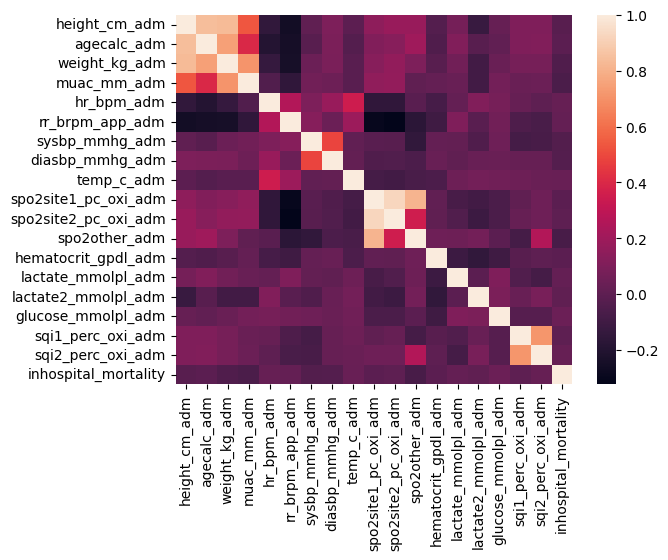

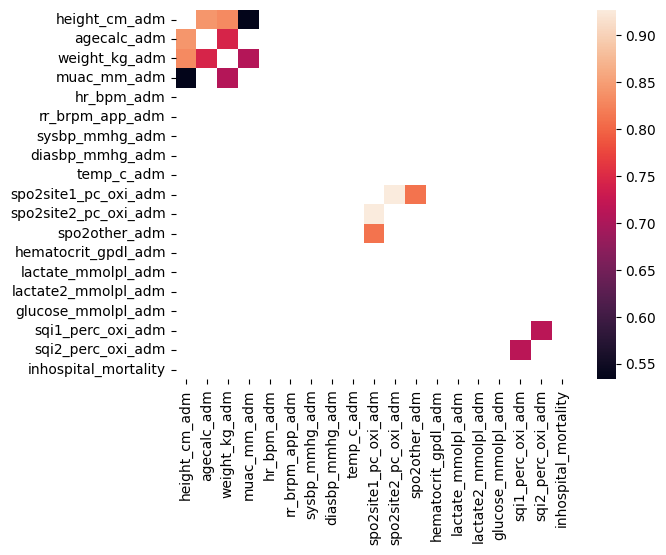

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt
corr_matrix = df.corr()
sns.heatmap(corr_matrix)
plt.show()
filtered_corr = corr_matrix.abs()[(corr_matrix.abs() > 0.5) & (corr_matrix != 1)]
sns.heatmap(filtered_corr)
plt.show()

In [38]:
corr_matrix

,height_cm_adm,agecalc_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,spo2site1_pc_oxi_adm,spo2site2_pc_oxi_adm,spo2other_adm,hematocrit_gpdl_adm,lactate_mmolpl_adm,lactate2_mmolpl_adm,glucose_mmolpl_adm,sqi1_perc_oxi_adm,sqi2_perc_oxi_adm,inhospital_mortality
height_cm_adm,1.000000,0.841617,0.831735,0.533257,-0.151324,-0.259520,0.005409,0.097955,-0.003751,0.149364,0.181774,0.180096,-0.030963,0.074601,-0.123626,0.025072,0.105913,0.103895,-0.021233
agecalc_adm,0.841617,1.000000,0.743102,0.400711,-0.197586,-0.248693,-0.017732,0.091281,-0.030692,0.107213,0.131711,0.199657,-0.045310,0.106439,-0.021751,0.010481,0.101350,0.107763,-0.012000
weight_kg_adm,0.831735,0.743102,1.000000,0.708281,-0.135495,-0.240409,0.041422,0.088525,-0.016616,0.130771,0.158211,0.098609,-0.020222,0.063663,-0.094931,0.034871,0.076571,0.077591,-0.046257
muac_mm_adm,0.533257,0.400711,0.708281,1.000000,-0.041860,-0.152137,0.063536,0.046581,-0.016564,0.155085,0.165021,0.005268,0.022814,0.032556,-0.093260,0.069434,0.034747,0.042333,-0.062270
hr_bpm_adm,-0.151324,-0.197586,-0.135495,-0.041860,1.000000,0.260458,0.096068,0.182943,0.345564,-0.153289,-0.154509,-0.016403,-0.077225,0.020921,0.109575,0.075837,0.024669,-0.000966,0.028669
rr_brpm_app_adm,-0.259520,-0.248693,-0.240409,-0.152137,0.260458,1.000000,0.122782,0.041159,0.192668,-0.300109,-0.322431,-0.170968,-0.103747,0.102777,-0.017093,0.061012,-0.053350,-0.068166,0.022213
sysbp_mmhg_adm,0.005409,-0.017732,0.041422,0.063536,0.096068,0.122782,1.000000,0.484975,0.012837,-0.014585,-0.022456,-0.147300,0.022059,0.015456,-0.048133,0.051010,-0.083677,-0.070316,-0.033598
diasbp_mmhg_adm,0.097955,0.091281,0.088525,0.046581,0.182943,0.041159,0.484975,1.000000,0.015994,-0.047779,-0.041952,-0.055783,0.033848,0.005073,0.030465,0.034347,0.028739,0.025194,-0.031281
temp_c_adm,-0.003751,-0.030692,-0.016616,-0.016564,0.345564,0.192668,0.012837,0.015994,1.000000,-0.084330,-0.091705,-0.064196,-0.057166,0.047943,0.067930,0.058268,0.047944,0.036571,0.033149
spo2site1_pc_oxi_adm,0.149364,0.107213,0.130771,0.155085,-0.153289,-0.300109,-0.014585,-0.047779,-0.084330,1.000000,0.927369,0.810885,0.009532,-0.069480,-0.091006,-0.061376,0.006775,0.050265,-0.008390


In [39]:
import pandas as pd

def group_correlated_features_simple(df, threshold=0.6):
    """
    Groups correlated features together (simple version using corr()).

    Args:
        df: Pandas DataFrame with numerical features.
        threshold: Correlation threshold.

    Returns:
        A dictionary where keys are group numbers and values are lists of feature names.
        Returns an empty dictionary if no correlations above threshold are found.
    """
    corr_matrix = df.corr().abs()
    correlated_groups = {}
    group_number = 1
    assigned_features = set()  # Keep track of assigned features

    for i in range(len(corr_matrix.columns)):
        feature = corr_matrix.columns[i]
        if feature not in assigned_features:
            group = [feature]
            for j in range(i + 1, len(corr_matrix.columns)): # Avoid duplicates
                other_feature = corr_matrix.columns[j]
                if abs(corr_matrix.iloc[i, j]) > threshold: # Directly use iloc
                    group.append(other_feature)
                    assigned_features.add(other_feature)
            if group: # Only add non-empty groups
                correlated_groups[group_number] = group
                group_number += 1
            assigned_features.add(feature)  # Mark current feature as assigned

    return correlated_groups

correlated_features = group_correlated_features_simple(df, threshold=0.3)
for k, v in correlated_features.items():
    print(k, v)

1 ['height_cm_adm', 'agecalc_adm', 'weight_kg_adm', 'muac_mm_adm']
2 ['hr_bpm_adm', 'temp_c_adm']
3 ['rr_brpm_app_adm', 'spo2site1_pc_oxi_adm', 'spo2site2_pc_oxi_adm']
4 ['sysbp_mmhg_adm', 'diasbp_mmhg_adm']
5 ['spo2other_adm']
6 ['hematocrit_gpdl_adm']
7 ['lactate_mmolpl_adm']
8 ['lactate2_mmolpl_adm']
9 ['glucose_mmolpl_adm']
10 ['sqi1_perc_oxi_adm', 'sqi2_perc_oxi_adm']
11 ['inhospital_mortality']


## Using the Iterative Imputer
* Groups:
    * height_cm_adm, agecalc_adm, weight_kg_adm, muac_mm_adm
    * **agecalc_adm**, hr_bpm_adm, rr_brpm_app_adm, temp_c_adm, height_cm_adm
    * **agecalc_adm**, **gender**, sysbp_mmhg_adm, diasbp_mmhg_adm, *hr_bpm_adm*
    * spo2site1_pc_oxi_adm, spo2site2_pc_oxi_adm, spo2other_adm, *rr_brpm_app_adm*, *hr_bpm_adm*
    * **agecalc_adm**, hematocrit_gpdl_adm, glucose_mmolpl_adm, lactate_mmolpl_adm, lactate2_mmolpl_adm, *rr_brpm_app_adm*

In [40]:
import pandas as pd
import numpy as np
from sklearn.impute import IterativeImputer

# not needed but included for completeness

class MultiFeatureImputer:
    def __init__(self, max_iter=10, random_state=42):
        self.medians_by_age_group = {}
        
        self.age_bins = [0, 2, 5, 11, 23, 35, 47, 59, 65]
        self.age_labels = [
           0 , # 'Newborn (0-2m)'
           1 , # 'Infant (3-5m)'
           2 , # 'Baby (6-11m)'
           3 , # 'Toddler (12-23m)'
           4 , # 'Preschool-2 (24-35m)'
           5 , # 'Preschool-3 (36-47m)'
           6 , # 'Preschool-4 (48-59m)'
           7 , # '5 years (60m)'
        ]
        # Dictionary of standard values
        self.standard_values = {
            # https://myhealth.alberta.ca/Health/pages/conditions.aspx?hwid=abo2987&lang=en-ca#abo2987-Bib
            'standard_low_hr_bpm_adm': {0: 70, 1: 70, 2: 70, 3: 52, 4: 52, 5: 52, 6: 52, 7: 52},
            'standard_high_hr_bpm_adm': {0: 190, 1: 190, 2: 190, 3: 156, 4: 156, 5: 156, 6: 156, 7: 156},
            
            # https://www.healthlinkbc.ca/healthwise/vital-signs-children
            # https://myhealth.alberta.ca/Health/pages/conditions.aspx?hwid=abo2987
            'standard_low_rr_brpm_app_adm': {0: 25, 1: 25, 2: 22, 3: 21, 4: 21, 5: 17, 6: 17, 7: 17},
            'standard_high_rr_brpm_app_adm': {0: 64, 1: 64, 2: 61, 3: 33, 4: 33, 5: 25, 6: 25, 7: 25},

            # https://medicine.uiowa.edu/iowaprotocols/pediatric-vital-signs-normal-ranges					
            # https://www.childrensmercy.org/siteassets/media-documents-for-depts-section/documents-for-health-care-providers/..
            # evidence-based-practice/clinical-practice-guidelines--care-process-models/normal-blood-pressures-by-age.pdf							
            'standard_low_sysbp_mmhg_adm': {0: 60, 1: 78,  2: 82, 3: 85, 4: 89, 5: 90, 6: 92, 7: 93},
            'standard_high_sysbp_mmhg_adm': {0: 94, 1: 103,  2: 105, 3: 102, 4: 106, 5: 107, 6: 108, 7: 110},
            'standard_low_diasbp_mmhg_adm': {0: 30, 1: 44,  2: 45, 3: 41, 4: 44, 5: 47, 6: 50, 7: 53},
            'standard_high_diasbp_mmhg_adm': {0: 56, 1: 65,  2: 68, 3: 58, 4: 62, 5: 65, 6: 67, 7: 70},
            
            # https://www.accp.com/docs/sap/Lab_values_Table_PedSAP.pdf
            'standard_low_hematocrit_gpdl_adm': {0: 44, 1: 32, 2: 32, 3: 32, 4: 33, 5: 33, 6: 33, 7: 33},
            'standard_high_hematocrit_gpdl_adm': {0: 70, 1: 42, 2: 42, 3: 42, 4: 43, 5: 43, 6: 43, 7: 43},
        }

        ## Group 0 imputer
        self.imputer_group_0 = IterativeImputer(max_iter=max_iter, random_state=random_state)
        self.features_group_0 = ['agecalc_adm', 'height_cm_adm', 'weight_kg_adm', 'muac_mm_adm']

        ## Group 1 imputer
        self.imputer_group_1 = IterativeImputer(max_iter=max_iter, random_state=random_state)
        self.features_group_1 = ['hr_bpm_adm', 
                         'rr_brpm_app_adm', 
                         'temp_c_adm', 
                         'height_cm_adm', 
                         'age_group',
                         'standard_low_hr_bpm_adm',
                         'standard_high_hr_bpm_adm',
                         'standard_low_rr_brpm_app_adm',
                         'standard_high_rr_brpm_app_adm']

        ## Group 2 imputer
        self.imputer_group_2 = IterativeImputer(max_iter=max_iter, random_state=random_state)
        self.features_group_2 = ['sysbp_mmhg_adm',
                                 'diasbp_mmhg_adm',
                                 'hr_bpm_adm', 
                                 #  'sex_adm',
                                 'age_group',
                                 'standard_low_sysbp_mmhg_adm',
                                 'standard_high_sysbp_mmhg_adm',
                                 'standard_low_diasbp_mmhg_adm',
                                 'standard_high_diasbp_mmhg_adm']

        ## Group 3 imputer
        self.imputer_group_3 = IterativeImputer(max_iter=max_iter, random_state=random_state)
        self.features_group_3 = ['spo2site1_pc_oxi_adm',
                                 'spo2site2_pc_oxi_adm',
                                 'spo2other_adm',
                                 'hr_bpm_adm', 
                                 'rr_brpm_app_adm']

        ## Group 4 imputer
        self.imputer_group_4 = IterativeImputer(max_iter=max_iter, random_state=random_state)
        self.features_group_4 = ['hematocrit_gpdl_adm', 
                                 'glucose_mmolpl_adm', 
                                 'lactate_mmolpl_adm', 
                                 'lactate2_mmolpl_adm',
                                 'rr_brpm_app_adm',
                                 'age_group', 
                                 'standard_low_hematocrit_gpdl_adm',
                                 'standard_high_hematocrit_gpdl_adm']
        
    def _map_standard_values(self, X: pd.DataFrame) -> pd.DataFrame:
        """Helper function to map standard values based on age group."""
        for column, mapping in self.standard_values.items():
            X[column] = X['age_group'].map(mapping)
        return X
    
    def fit(self, X_train, y=None):
        """Fits the imputer on training data."""
        X = X_train.copy()

        # Drop unnecessary columns
        X.drop(columns=['studyid_adm', 'lengthadm'],
                  errors='ignore', inplace=True)

        # Define age groups
        X['age_group'] = pd.cut(
            X['agecalc_adm'],
            bins=self.age_bins,
            labels=self.age_labels,
            right=True
        )
        
        # Compute medians for numerical columns by age group
        columns_to_fill_by_median = []
        
        for column in columns_to_fill_by_median:
            self.medians_by_age_group[column] = X.groupby('age_group')[
                column].median()
        
        # Map standard values
        X = self._map_standard_values(X)

        # fit/train the imputer
        self.imputer_group_0.fit(X[self.features_group_0])
        self.imputer_group_1.fit(X[self.features_group_1])
        self.imputer_group_2.fit(X[self.features_group_2])
        self.imputer_group_3.fit(X[self.features_group_3])
        self.imputer_group_4.fit(X[self.features_group_4])
        return self

    def transform(self, X):
        """Applies learned imputation model to new data."""
        X = X.copy()

        # Drop unnecessary columns
        X.drop(columns=['studyid_adm', 'lengthadm'],
                  errors='ignore', inplace=True)
        
        # Define age groups
        X['age_group'] = pd.cut(
            X['agecalc_adm'],
            bins=self.age_bins,
            labels=self.age_labels,
            right=True
        )

        # Fill missing values by median of age groups
        for column, medians in self.medians_by_age_group.items():
            X[column] = X.apply(
                lambda row: medians[row['age_group']] if pd.isnull(
                    row[column]) else row[column],
                axis=1
            )
        
        # Map standard values
        X = self._map_standard_values(X)

        # imputer transformation
        X[self.features_group_0] = self.imputer_group_0.transform(X[self.features_group_0])
        X[self.features_group_1] = self.imputer_group_1.transform(X[self.features_group_1])
        X[self.features_group_2] = self.imputer_group_2.transform(X[self.features_group_2])
        X[self.features_group_3] = self.imputer_group_3.transform(X[self.features_group_3])
        X[self.features_group_4] = self.imputer_group_4.transform(X[self.features_group_4])
        
        # Drop unnecessary columns
        X.drop(columns=self.standard_values.keys(), inplace=True, errors='ignore')
        
        return X

    def fit_transform(self, X, y=None):
        """Fits and transforms in one step."""
        return self.fit(X).transform(X)

In [41]:
tmp = df[df['sqi1_perc_oxi_adm'].notna() & df['sqi2_perc_oxi_adm'].notna()][[
    'sqi1_perc_oxi_adm', 
    'sqi2_perc_oxi_adm', 
    'spo2site1_pc_oxi_adm',
    'spo2site2_pc_oxi_adm',
    'spo2other_adm']]

# import seaborn as sns
# import matplotlib.pyplot as plt
# corr_matrix = tmp.corr()
# sns.heatmap(corr_matrix)
# plt.show()
# filtered_corr = corr_matrix.abs()[(corr_matrix.abs() > 0.1) & (corr_matrix != 1)]
# sns.heatmap(filtered_corr)
# plt.show()

In [42]:
imputer = MultiFeatureImputer()
X = df.drop(columns=["inhospital_mortality"])
y = df["inhospital_mortality"]
features = X.columns

for f in features:
    print(f, X[f].isna().sum())
imputer.fit(X)
X_transformed = imputer.transform(X)

print("\n\n\n")
for f in features:
    print(f, X_transformed[f].isna().sum())

height_cm_adm 9
agecalc_adm 0
weight_kg_adm 5
muac_mm_adm 9
hr_bpm_adm 1
rr_brpm_app_adm 4
sysbp_mmhg_adm 0
diasbp_mmhg_adm 1
temp_c_adm 1
spo2site1_pc_oxi_adm 4
spo2site2_pc_oxi_adm 159
spo2other_adm 2000
hematocrit_gpdl_adm 365
lactate_mmolpl_adm 366
lactate2_mmolpl_adm 1779
glucose_mmolpl_adm 9
sqi1_perc_oxi_adm 108
sqi2_perc_oxi_adm 160




height_cm_adm 0
agecalc_adm 0
weight_kg_adm 0
muac_mm_adm 0
hr_bpm_adm 0
rr_brpm_app_adm 0
sysbp_mmhg_adm 0
diasbp_mmhg_adm 0
temp_c_adm 0
spo2site1_pc_oxi_adm 0
spo2site2_pc_oxi_adm 0
spo2other_adm 0
hematocrit_gpdl_adm 0
lactate_mmolpl_adm 0
lactate2_mmolpl_adm 0
glucose_mmolpl_adm 0
sqi1_perc_oxi_adm 108
sqi2_perc_oxi_adm 160


In [43]:
X_transformed.to_csv("tmp_datasets/numerical_cleaned.csv", index=False)